In [1]:
import random

# 1. KHỞI TẠO HỆ THỐNG (3 Máy chủ biên với cấu hình & độ trễ mạng khác nhau)
servers = [
    {"name": "Máy chủ 1 (Mạnh, ở xa)",  "cpu": 100, "net_delay": 0.5, "queue": 0},
    {"name": "Máy chủ 2 (Vừa, ở gần)",  "cpu": 60,  "net_delay": 0.1, "queue": 0},
    {"name": "Máy chủ 3 (Yếu, rất gần)", "cpu": 40,  "net_delay": 0.05,"queue": 0}
]

# 2. BỘ ĐIỀU PHỐI THÔNG MINH (Cân bằng giữa Tải và Độ trễ)
def chon_may_chu(task_size, servers):
    best_server = None
    min_total_time = float('inf') # Thời gian nhỏ nhất (khởi tạo vô cực)

    for s in servers:
        # Tính thời gian chờ (Tải hiện tại) = Hàng đợi / Tốc độ CPU
        wait_time = s["queue"] / s["cpu"]
        # Tính thời gian xử lý tác vụ mới = Kích thước tác vụ / Tốc độ CPU
        exec_time = task_size / s["cpu"]
        # Tổng độ trễ = Trễ mạng + Thời gian chờ (Tải) + Thời gian xử lý
        total_time = s["net_delay"] + wait_time + exec_time

        if total_time < min_total_time:
            min_total_time = total_time
            best_server = s

    return best_server, min_total_time

# 3. CHẠY MÔ PHỎNG VỚI 10 TÁC VỤ LIÊN TIẾP
print("--- BẮT ĐẦU MÔ PHỎNG PHÂN PHỐI TÁC VỤ ---\n")
for i in range(1, 11):
    # Thiết bị sinh ra tác vụ ngẫu nhiên (kích thước từ 10 đến 50)
    task_size = random.randint(10, 50)

    # Bộ điều phối ra quyết định
    selected_server, delay = chon_may_chu(task_size, servers)

    # Cộng dồn tác vụ vào hàng đợi (tăng tải) của máy chủ được chọn
    selected_server["queue"] += task_size

    print(f"Tác vụ {i:02d} (Nặng {task_size}) -> Đưa vào [{selected_server['name']}] "
          f"| Tổng trễ dự kiến: {delay:.2f}s | Tải hàng đợi mới: {selected_server['queue']}")

print("\n--- TỔNG KẾT TẢI TRÊN CÁC MÁY CHỦ ---")
for s in servers:
    print(f"{s['name']}: Tổng khối lượng việc đã nhận = {s['queue']}")


--- BẮT ĐẦU MÔ PHỎNG PHÂN PHỐI TÁC VỤ ---

Tác vụ 01 (Nặng 16) -> Đưa vào [Máy chủ 2 (Vừa, ở gần)] | Tổng trễ dự kiến: 0.37s | Tải hàng đợi mới: 16
Tác vụ 02 (Nặng 49) -> Đưa vào [Máy chủ 1 (Mạnh, ở xa)] | Tổng trễ dự kiến: 0.99s | Tải hàng đợi mới: 49
Tác vụ 03 (Nặng 23) -> Đưa vào [Máy chủ 3 (Yếu, rất gần)] | Tổng trễ dự kiến: 0.62s | Tải hàng đợi mới: 23
Tác vụ 04 (Nặng 24) -> Đưa vào [Máy chủ 2 (Vừa, ở gần)] | Tổng trễ dự kiến: 0.77s | Tải hàng đợi mới: 40
Tác vụ 05 (Nặng 14) -> Đưa vào [Máy chủ 3 (Yếu, rất gần)] | Tổng trễ dự kiến: 0.97s | Tải hàng đợi mới: 37
Tác vụ 06 (Nặng 36) -> Đưa vào [Máy chủ 1 (Mạnh, ở xa)] | Tổng trễ dự kiến: 1.35s | Tải hàng đợi mới: 85
Tác vụ 07 (Nặng 22) -> Đưa vào [Máy chủ 2 (Vừa, ở gần)] | Tổng trễ dự kiến: 1.13s | Tải hàng đợi mới: 62
Tác vụ 08 (Nặng 14) -> Đưa vào [Máy chủ 3 (Yếu, rất gần)] | Tổng trễ dự kiến: 1.33s | Tải hàng đợi mới: 51
Tác vụ 09 (Nặng 46) -> Đưa vào [Máy chủ 1 (Mạnh, ở xa)] | Tổng trễ dự kiến: 1.81s | Tải hàng đợi mới: 131
Tác v

BỔ SUNG MINH HỌA TRỰC QUAN

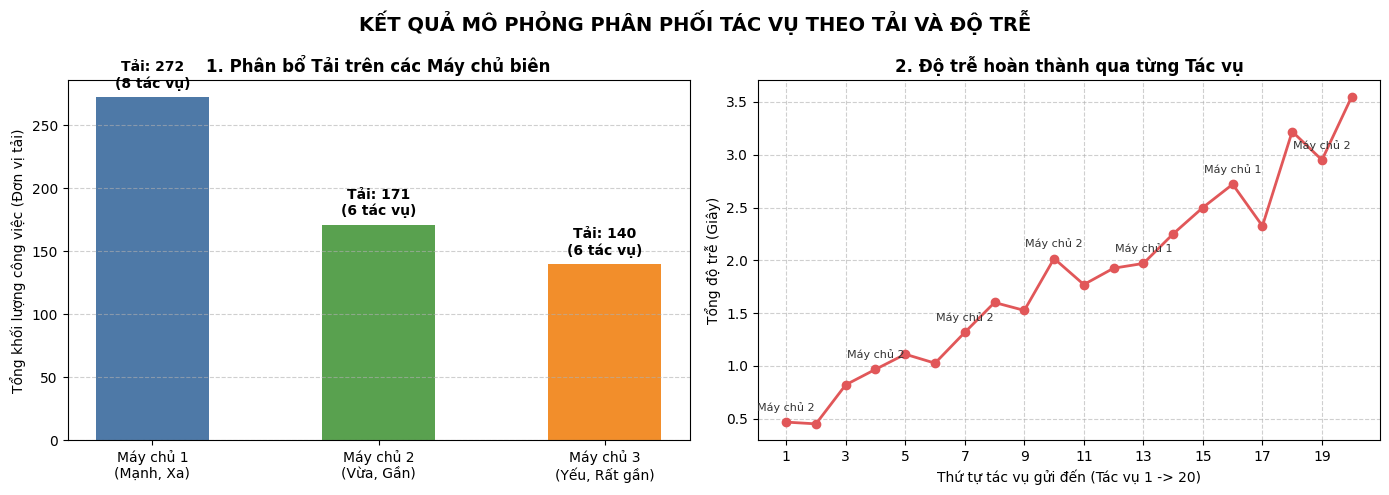

In [2]:
import random
import matplotlib.pyplot as plt
import numpy as np

# Cố định hạt giống ngẫu nhiên để mỗi lần chạy ra kết quả dễ theo dõi
random.seed(42)

# 1. KHỞI TẠO HỆ THỐNG (3 Máy chủ biên)
servers = [
    {"name": "Máy chủ 1\n(Mạnh, Xa)",  "cpu": 100, "net_delay": 0.5,  "queue": 0, "tasks": 0},
    {"name": "Máy chủ 2\n(Vừa, Gần)",  "cpu": 60,  "net_delay": 0.1,  "queue": 0, "tasks": 0},
    {"name": "Máy chủ 3\n(Yếu, Rất gần)", "cpu": 40,  "net_delay": 0.05, "queue": 0, "tasks": 0}
]

# 2. BỘ ĐIỀU PHỐI THÔNG MINH (Theo Tải & Độ trễ)
def chon_may_chu(task_size, servers):
    best_server = None
    min_total_time = float('inf')

    for s in servers:
        wait_time = s["queue"] / s["cpu"]      # Thời gian chờ (Tải hiện tại)
        exec_time = task_size / s["cpu"]       # Thời gian xử lý tác vụ mới
        total_time = s["net_delay"] + wait_time + exec_time # Tổng độ trễ

        if total_time < min_total_time:
            min_total_time = total_time
            best_server = s

    return best_server, min_total_time

# 3. CHẠY MÔ PHỎNG VỚI 20 TÁC VỤ
num_tasks = 20
history_delays = []   # Lưu độ trễ từng tác vụ để vẽ biểu đồ
history_servers = []  # Lưu tên máy chủ được chọn

for i in range(1, num_tasks + 1):
    task_size = random.randint(15, 50) # Kích thước tác vụ ngẫu nhiên
    selected_server, delay = chon_may_chu(task_size, servers)

    # Cập nhật trạng thái máy chủ
    selected_server["queue"] += task_size
    selected_server["tasks"] += 1

    # Lưu lịch sử
    history_delays.append(delay)
    history_servers.append(selected_server["name"].split("\n")[0])

# 4. VẼ BIỂU ĐỒ TRỰC QUAN TRÊN GOOGLE COLAB
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("KẾT QUẢ MÔ PHỎNG PHÂN PHỐI TÁC VỤ THEO TẢI VÀ ĐỘ TRỄ", fontsize=14, fontweight='bold')

# --- Biểu đồ 1: Tổng tải (khối lượng công việc) phân bổ trên từng máy chủ ---
names = [s["name"] for s in servers]
queues = [s["queue"] for s in servers]
task_counts = [s["tasks"] for s in servers]
colors = ['#4e79a7', '#59a14f', '#f28e2b']

bars = ax1.bar(names, queues, color=colors, width=0.5)
ax1.set_title("1. Phân bổ Tải trên các Máy chủ biên", fontsize=12, fontweight='bold')
ax1.set_ylabel("Tổng khối lượng công việc (Đơn vị tải)")
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Hiển thị con số cụ thể trên đầu mỗi cột
for bar, count in zip(bars, task_counts):
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 5,
             f"Tải: {yval}\n({count} tác vụ)", ha='center', va='bottom', fontweight='bold')

# --- Biểu đồ 2: Độ trễ xử lý qua từng tác vụ ---
x_tasks = range(1, num_tasks + 1)
ax2.plot(x_tasks, history_delays, marker='o', linestyle='-', color='#e15759', linewidth=2)
ax2.set_title("2. Độ trễ hoàn thành qua từng Tác vụ", fontsize=12, fontweight='bold')
ax2.set_xlabel("Thứ tự tác vụ gửi đến (Tác vụ 1 -> 20)")
ax2.set_ylabel("Tổng độ trễ (Giây)")
ax2.set_xticks(range(1, num_tasks + 1, 2))
ax2.grid(True, linestyle='--', alpha=0.6)

# Ghi chú tên máy chủ được chọn cho vài điểm tiêu biểu
for i in range(0, num_tasks, 3):
    ax2.annotate(history_servers[i], (x_tasks[i], history_delays[i]),
                 textcoords="offset points", xytext=(0,8), ha='center', fontsize=8, color='#333333')

plt.tight_layout()
plt.show()


thêm yếu tố thời gian thực

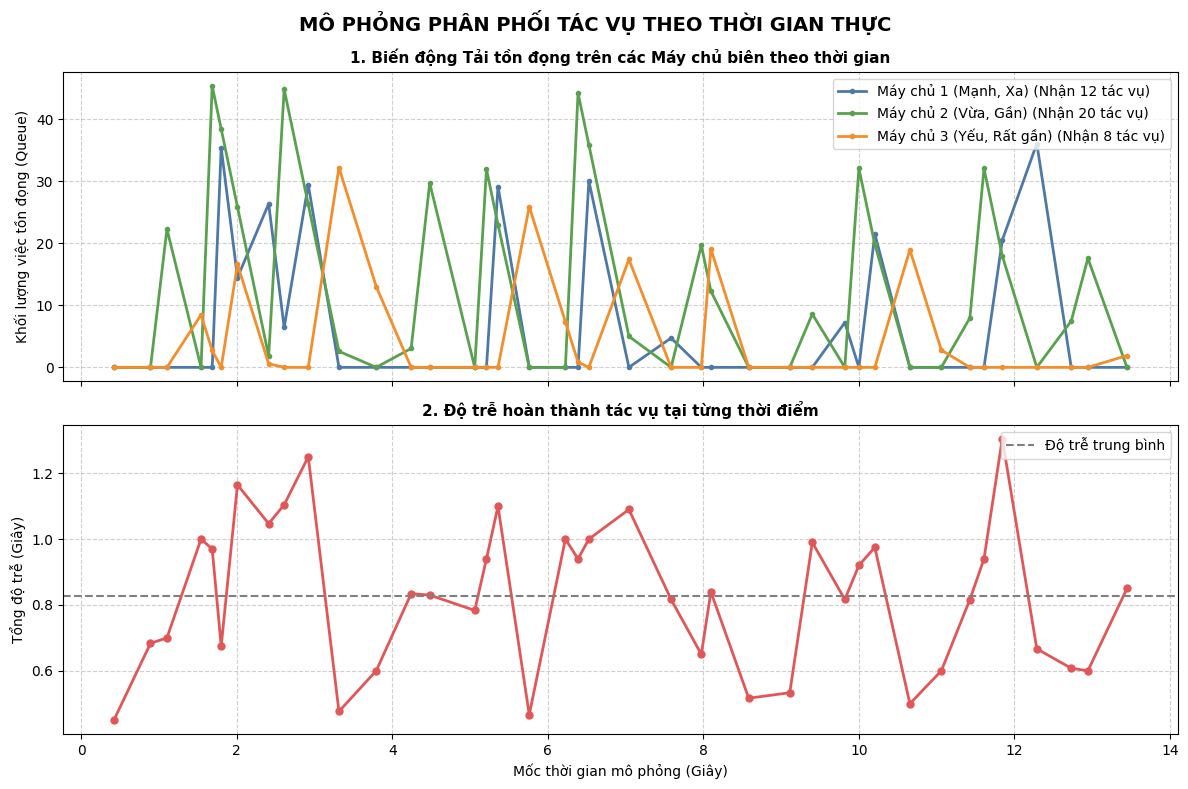

In [3]:
import random
import matplotlib.pyplot as plt

# Cố định hạt giống ngẫu nhiên để dễ theo dõi kết quả
random.seed(42)

# 1. KHỞI TẠO HỆ THỐNG (3 Máy chủ biên)
servers = [
    {"name": "Máy chủ 1 (Mạnh, Xa)",  "cpu": 100, "net_delay": 0.5,  "queue": 0.0, "total_tasks": 0},
    {"name": "Máy chủ 2 (Vừa, Gần)",  "cpu": 60,  "net_delay": 0.1,  "queue": 0.0, "total_tasks": 0},
    {"name": "Máy chủ 3 (Yếu, Rất gần)", "cpu": 40,  "net_delay": 0.05, "queue": 0.0, "total_tasks": 0}
]

# 2. BỘ ĐIỀU PHỐI THÔNG MINH (Theo Tải hiện tại & Độ trễ)
def chon_may_chu(task_size, servers):
    best_server = None
    min_total_time = float('inf')

    for s in servers:
        wait_time = s["queue"] / s["cpu"]      # Thời gian chờ từ hàng đợi hiện tại
        exec_time = task_size / s["cpu"]       # Thời gian xử lý tác vụ mới
        total_time = s["net_delay"] + wait_time + exec_time

        if total_time < min_total_time:
            min_total_time = total_time
            best_server = s

    return best_server, min_total_time

# 3. MÔ PHỎNG THEO THỜI GIAN THỰC (40 tác vụ)
num_tasks = 40
current_time = 0.0

# Mảng lưu lịch sử để vẽ biểu đồ
timestamps = []
history_delays = []
history_queues = {s["name"]: [] for s in servers}

for i in range(1, num_tasks + 1):
    # Khoảng thời gian trôi qua giữa 2 lần gửi tác vụ (từ 0.1s đến 0.6s)
    # Có những lúc tác vụ dồn dập (0.1s), có lúc thưa thớt (0.6s)
    time_passed = random.uniform(0.1, 0.6)
    current_time += time_passed

    # CẬP NHẬT THỜI GIAN THỰC: Các máy chủ xử lý bớt việc trong khoảng time_passed
    for s in servers:
        processed_work = s["cpu"] * time_passed
        s["queue"] = max(0.0, s["queue"] - processed_work) # Hàng đợi giảm dần, tối thiểu bằng 0
        history_queues[s["name"]].append(s["queue"])       # Lưu lại mức tải tại thời điểm này

    # Phát sinh tác vụ mới và phân phối
    task_size = random.randint(20, 60)
    selected_server, delay = chon_may_chu(task_size, servers)

    # Cộng tác vụ mới vào hàng đợi của máy được chọn
    selected_server["queue"] += task_size
    selected_server["total_tasks"] += 1

    timestamps.append(current_time)
    history_delays.append(delay)

# 4. VẼ BIỂU ĐỒ TRỰC QUAN THEO DÒNG THỜI GIAN
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.suptitle("MÔ PHỎNG PHÂN PHỐI TÁC VỤ THEO THỜI GIAN THỰC", fontsize=14, fontweight='bold')

# --- Biểu đồ 1: Biến động Tải (Hàng đợi) của 3 máy chủ theo thời gian ---
colors = ['#4e79a7', '#59a14f', '#f28e2b']
for s, color in zip(servers, colors):
    ax1.plot(timestamps, history_queues[s["name"]], label=f"{s['name']} (Nhận {s['total_tasks']} tác vụ)",
             color=color, linewidth=2, marker='.', markersize=6)

ax1.set_title("1. Biến động Tải tồn đọng trên các Máy chủ biên theo thời gian", fontsize=11, fontweight='bold')
ax1.set_ylabel("Khối lượng việc tồn đọng (Queue)")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle='--', alpha=0.6)

# --- Biểu đồ 2: Độ trễ xử lý tại từng thời điểm ---
ax2.plot(timestamps, history_delays, color='#e15759', linewidth=2, marker='o', markersize=5)
ax2.axhline(sum(history_delays)/len(history_delays), color='gray', linestyle='--', label='Độ trễ trung bình')
ax2.set_title("2. Độ trễ hoàn thành tác vụ tại từng thời điểm", fontsize=11, fontweight='bold')
ax2.set_xlabel("Mốc thời gian mô phỏng (Giây)")
ax2.set_ylabel("Tổng độ trễ (Giây)")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


so sánh trực tiếp thuật toán của bạn (Theo Tải & Độ trễ) với 2 thuật toán cơ sở phổ biến nhất là Ngẫu nhiên (Random) và Xoay vòng (Round Robin).
Để đảm bảo tính công bằng tuyệt đối khi đánh giá, cả 3 thuật toán sẽ cùng giải quyết một tập dữ liệu tác vụ và mốc thời gian giống hệt nhau.



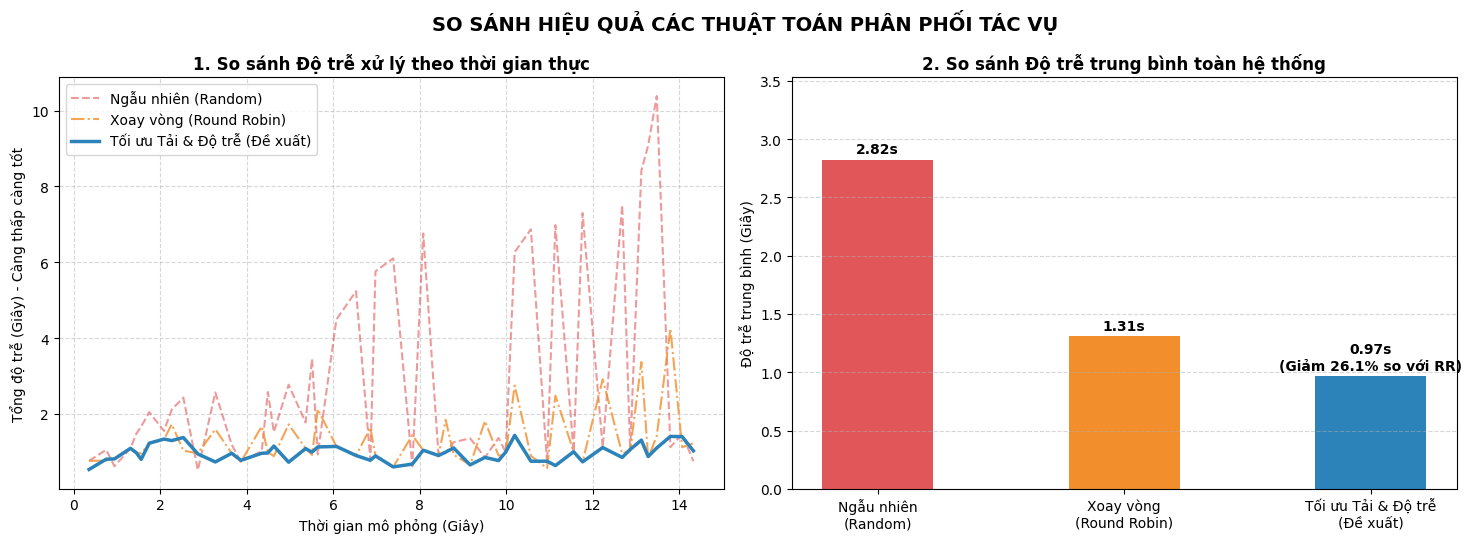

In [4]:
import random
import copy
import matplotlib.pyplot as plt
import numpy as np

# 1. TẠO KỊCH BẢN DỮ LIỆU CHUNG (50 tác vụ theo thời gian thực)
random.seed(42)
num_tasks = 50
workload = []
current_time = 0.0

for _ in range(num_tasks):
    time_passed = random.uniform(0.1, 0.5) # Tốc độ gửi tác vụ dồn dập hơn một chút
    current_time += time_passed
    task_size = random.randint(25, 65)
    workload.append({"time_passed": time_passed, "timestamp": current_time, "size": task_size})

# Cấu hình 3 máy chủ biên gốc
base_servers = [
    {"name": "Máy chủ 1", "cpu": 100, "net_delay": 0.5,  "queue": 0.0},
    {"name": "Máy chủ 2", "cpu": 60,  "net_delay": 0.1,  "queue": 0.0},
    {"name": "Máy chủ 3", "cpu": 40,  "net_delay": 0.05, "queue": 0.0}
]

# 2. HÀM CHẠY MÔ PHỎNG CHO TỪNG THUẬT TOÁN
def run_simulation(strategy):
    servers = copy.deepcopy(base_servers) # Reset lại trạng thái máy chủ sạch sẽ
    delays = []

    for idx, task in enumerate(workload):
        # Cập nhật thời gian thực: Các máy chủ xử lý bớt việc trong hàng đợi
        for s in servers:
            s["queue"] = max(0.0, s["queue"] - s["cpu"] * task["time_passed"])

        # Lựa chọn máy chủ theo từng chiến lược thuật toán
        if strategy == "Random":
            selected = random.choice(servers)
        elif strategy == "Round_Robin":
            selected = servers[idx % len(servers)]
        elif strategy == "Load_Latency_Aware":
            selected = min(servers, key=lambda s: s["net_delay"] + (s["queue"] + task["size"]) / s["cpu"])

        # Tính tổng độ trễ thực tế của tác vụ này
        total_delay = selected["net_delay"] + (selected["queue"] + task["size"]) / selected["cpu"]
        delays.append(total_delay)

        # Cộng tác vụ vào hàng đợi của máy được chọn
        selected["queue"] += task["size"]

    # Trả về danh sách độ trễ và độ lệch chuẩn hàng đợi cuối cùng (đo mức độ cân bằng tải)
    final_queues = [s["queue"] for s in servers]
    return delays, final_queues

# Chạy cả 3 thuật toán
delays_random, q_random = run_simulation("Random")
delays_rr, q_rr         = run_simulation("Round_Robin")
delays_smart, q_smart   = run_simulation("Load_Latency_Aware")

timestamps = [t["timestamp"] for t in workload]

# 3. VẼ 2 BIỂU ĐỒ SO SÁNH TRỰC QUAN
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle("SO SÁNH HIỆU QUẢ CÁC THUẬT TOÁN PHÂN PHỐI TÁC VỤ", fontsize=14, fontweight='bold')

# --- Biểu đồ 1: Diễn biến Độ trễ theo thời gian thực ---
ax1.plot(timestamps, delays_random, label="Ngẫu nhiên (Random)", color='#e15759', alpha=0.6, linestyle='--')
ax1.plot(timestamps, delays_rr, label="Xoay vòng (Round Robin)", color='#f28e2b', alpha=0.8, linestyle='-.')
ax1.plot(timestamps, delays_smart, label="Tối ưu Tải & Độ trễ (Đề xuất)", color='#2b83ba', linewidth=2.5)

ax1.set_title("1. So sánh Độ trễ xử lý theo thời gian thực", fontsize=12, fontweight='bold')
ax1.set_xlabel("Thời gian mô phỏng (Giây)")
ax1.set_ylabel("Tổng độ trễ (Giây) - Càng thấp càng tốt")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Biểu đồ 2: Độ trễ trung bình tổng thể (Biểu đồ cột) ---
strategies = ["Ngẫu nhiên\n(Random)", "Xoay vòng\n(Round Robin)", "Tối ưu Tải & Độ trễ\n(Đề xuất)"]
avg_delays = [np.mean(delays_random), np.mean(delays_rr), np.mean(delays_smart)]
bar_colors = ['#e15759', '#f28e2b', '#2b83ba']

bars = ax2.bar(strategies, avg_delays, color=bar_colors, width=0.45)
ax2.set_title("2. So sánh Độ trễ trung bình toàn hệ thống", fontsize=12, fontweight='bold')
ax2.set_ylabel("Độ trễ trung bình (Giây)")
ax2.set_ylim(0, max(avg_delays) * 1.25)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Ghi giá trị và % cải thiện lên đầu cột
for i, bar in enumerate(bars):
    yval = bar.get_height()
    if i == 2:
        improve = (avg_delays[1] - yval) / avg_delays[1] * 100
        label_text = f"{yval:.2f}s\n(Giảm {improve:.1f}% so với RR)"
    else:
        label_text = f"{yval:.2f}s"
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.03, label_text,
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


tHÊM CÂN BẲNG TẢI

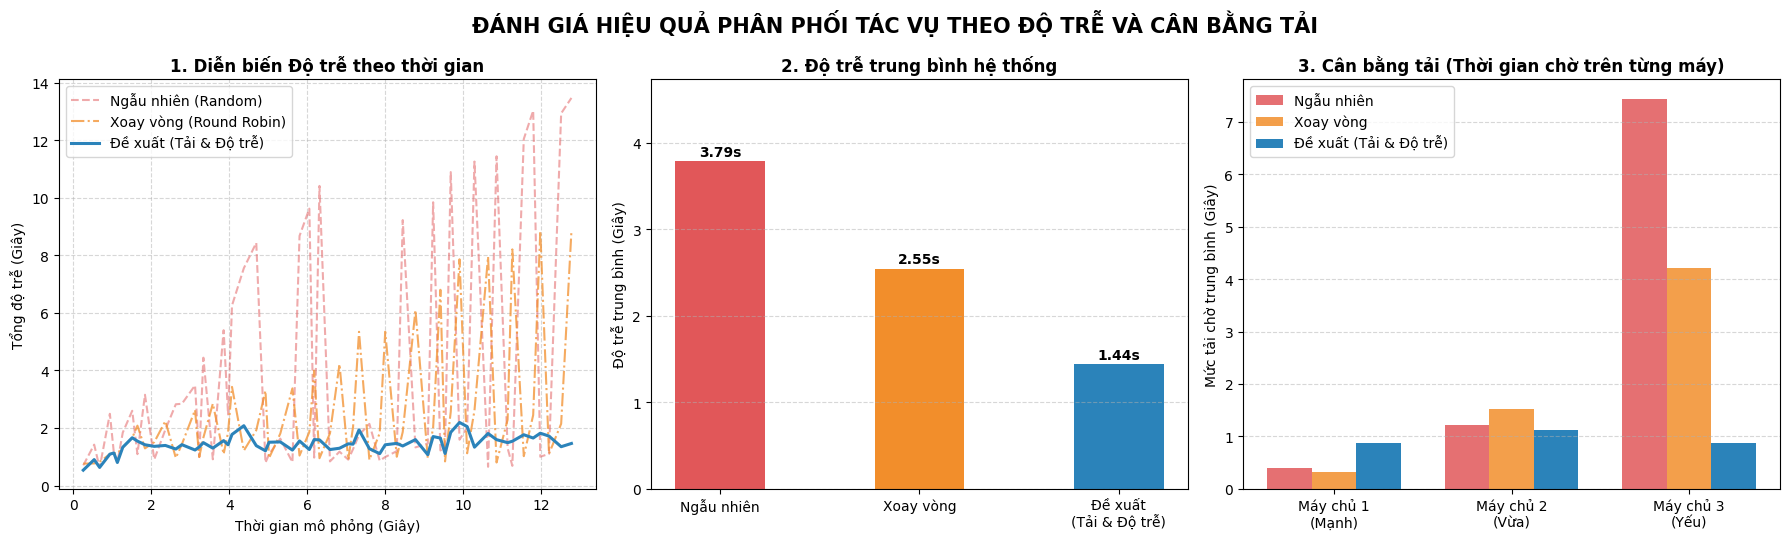

In [5]:
import random
import copy
import matplotlib.pyplot as plt
import numpy as np

# 1. TẠO KỊCH BẢN DỮ LIỆU CHUNG (60 tác vụ dồn dập theo thời gian thực)
random.seed(42)
num_tasks = 60
workload = []
current_time = 0.0

for _ in range(num_tasks):
    time_passed = random.uniform(0.08, 0.35) # Tốc độ gửi tác vụ nhanh để thấy rõ sự nghẽn tải
    current_time += time_passed
    task_size = random.randint(25, 65)
    workload.append({"time_passed": time_passed, "timestamp": current_time, "size": task_size})

# Cấu hình 3 máy chủ biên gốc
base_servers = [
    {"name": "Máy chủ 1\n(Mạnh)", "cpu": 100, "net_delay": 0.5,  "queue": 0.0},
    {"name": "Máy chủ 2\n(Vừa)",  "cpu": 60,  "net_delay": 0.1,  "queue": 0.0},
    {"name": "Máy chủ 3\n(Yếu)",  "cpu": 40,  "net_delay": 0.05, "queue": 0.0}
]

# 2. HÀM CHẠY MÔ PHỎNG & GHI NHẬN TẢI TRUNG BÌNH CỦA TỪNG MÁY
def run_simulation(strategy):
    servers = copy.deepcopy(base_servers)
    delays = []
    # Lưu lịch sử thời gian chờ (tải thực tế = queue / cpu) của từng máy tại mỗi bước
    load_history = {s["name"]: [] for s in servers}

    for idx, task in enumerate(workload):
        for s in servers:
            s["queue"] = max(0.0, s["queue"] - s["cpu"] * task["time_passed"])

        if strategy == "Random":
            selected = random.choice(servers)
        elif strategy == "Round_Robin":
            selected = servers[idx % len(servers)]
        elif strategy == "Load_Latency_Aware":
            selected = min(servers, key=lambda s: s["net_delay"] + (s["queue"] + task["size"]) / s["cpu"])

        total_delay = selected["net_delay"] + (selected["queue"] + task["size"]) / selected["cpu"]
        delays.append(total_delay)

        selected["queue"] += task["size"]

        # Ghi nhận mức tải (thời gian chờ xử lý hết hàng đợi) của cả 3 máy sau khi giao việc
        for s in servers:
            load_history[s["name"]].append(s["queue"] / s["cpu"])

    # Tính mức tải trung bình của từng máy trong suốt quá trình mô phỏng
    avg_server_loads = [np.mean(load_history[s["name"]]) for s in servers]
    return delays, avg_server_loads

# Chạy mô phỏng cho 3 thuật toán
delays_random, loads_random = run_simulation("Random")
delays_rr, loads_rr         = run_simulation("Round_Robin")
delays_smart, loads_smart   = run_simulation("Load_Latency_Aware")

timestamps = [t["timestamp"] for t in workload]

# 3. VẼ BỘ 3 BIỂU ĐỒ ĐÁNH GIÁ TOÀN DIỆN
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle("ĐÁNH GIÁ HIỆU QUẢ PHÂN PHỐI TÁC VỤ THEO ĐỘ TRỄ VÀ CÂN BẰNG TẢI", fontsize=15, fontweight='bold')

# --- Biểu đồ 1: Diễn biến Độ trễ theo thời gian thực ---
ax1.plot(timestamps, delays_random, label="Ngẫu nhiên (Random)", color='#e15759', alpha=0.5, linestyle='--')
ax1.plot(timestamps, delays_rr, label="Xoay vòng (Round Robin)", color='#f28e2b', alpha=0.75, linestyle='-.')
ax1.plot(timestamps, delays_smart, label="Đề xuất (Tải & Độ trễ)", color='#2b83ba', linewidth=2.2)
ax1.set_title("1. Diễn biến Độ trễ theo thời gian", fontsize=12, fontweight='bold')
ax1.set_xlabel("Thời gian mô phỏng (Giây)")
ax1.set_ylabel("Tổng độ trễ (Giây)")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Biểu đồ 2: Độ trễ trung bình tổng thể ---
strategies = ["Ngẫu nhiên", "Xoay vòng", "Đề xuất\n(Tải & Độ trễ)"]
avg_delays = [np.mean(delays_random), np.mean(delays_rr), np.mean(delays_smart)]
bars = ax2.bar(strategies, avg_delays, color=['#e15759', '#f28e2b', '#2b83ba'], width=0.45)
ax2.set_title("2. Độ trễ trung bình hệ thống", fontsize=12, fontweight='bold')
ax2.set_ylabel("Độ trễ trung bình (Giây)")
ax2.set_ylim(0, max(avg_delays) * 1.25)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for i, bar in enumerate(bars):
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.03, f"{yval:.2f}s",
             ha='center', va='bottom', fontweight='bold', fontsize=10)

# --- Biểu đồ 3: Mức độ Cân bằng tải giữa 3 Máy chủ (Grouped Bar Chart) ---
server_names = [s["name"] for s in base_servers]
x = np.arange(len(server_names))
width = 0.25

ax3.bar(x - width, loads_random, width, label='Ngẫu nhiên', color='#e15759', alpha=0.85)
ax3.bar(x,         loads_rr,     width, label='Xoay vòng',  color='#f28e2b', alpha=0.85)
ax3.bar(x + width, loads_smart,  width, label='Đề xuất (Tải & Độ trễ)', color='#2b83ba')

ax3.set_title("3. Cân bằng tải (Thời gian chờ trên từng máy)", fontsize=12, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(server_names)
ax3.set_ylabel("Mức tải chờ trung bình (Giây)")
ax3.legend()
ax3.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
